<a href="https://colab.research.google.com/github/HatamiM12/Machine-Learning-Training/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
#Import libreries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns

In [12]:
data = load_breast_cancer()
X, y = data.data[:, [2,4]], data.target
print(data.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [13]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train_raw)          # statistics come from training data only
X_train = np.hstack((scaler.transform(X_train_raw), np.ones((len(X_train_raw), 1))))  # columns: [perimeter, smoothness, bias]
X_test  = np.hstack((scaler.transform(X_test_raw),  np.ones((len(X_test_raw), 1))))
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 3) | Test: (114, 3)


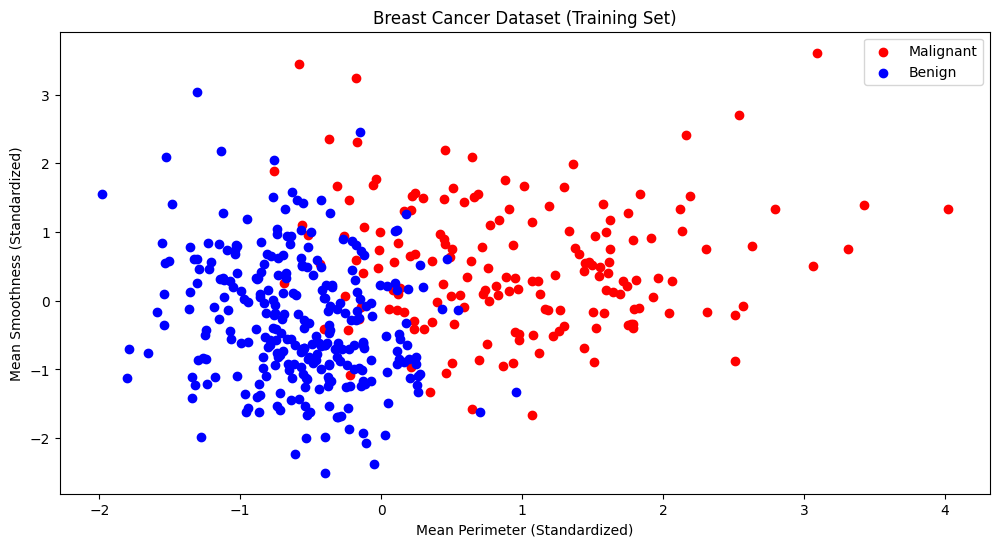

In [14]:
plt.figure(figsize=(12, 6))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color='red', label='Malignant')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color='blue', label='Benign')
plt.xlabel('Mean Perimeter (Standardized)')
plt.ylabel('Mean Smoothness (Standardized)')
plt.title('Breast Cancer Dataset (Training Set)')
plt.legend()
plt.show()

In [22]:
# Sigmoid activation function
def sigmoid(z):
  z = np.clip(z, -500, 500)   #Fix: avoid overfloe in exp for very negative z
  return 1 / (1 + np.exp(-z))

#Compute_loss function
def compute_loss(w, X, y):
  EPS = 1e-12
  z = X @ w
  prediction = sigmoid(z)
  p = np.clip(prediction, EPS, 1 - EPS)     # FIX: avoid log(0)
  loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
  return loss

#compute_gradient of the loss weight
def compute_gradient(w, X, y):
  z = X @ w
  prediction = sigmoid(z)
  errors = prediction - y
  gradient = X.T @ errors / len(y)
  return gradient

#Evaluate test accuracy
def test_accuracy(w, X_test, y_test):
  probabilities = sigmoid(X_test @ w)
  predictions = (probabilities > 0.5).astype(int)
  accuracy = np.mean(predictions == y_test)
  return accuracy

In [24]:
# Gradient descent for logistic regression
def gradient_decsent_logistic(X_train, X_test, y_train, y_test, learning_rate=0.1, n_steps=1000, tolerance=1e-6):
  #Initialize weights
  w = np.zeros(X_train.shape[1])
  # Track loss, accuracy, and weights
  loss_history = [compute_loss(w, X_train, y_train)]
  test_accuracy_history = [test_accuracy(w, X_test, y_test)]
  weights_history = [w.copy()]

  #training loop
  for step in range(1, n_steps + 1):
    grad = compute_gradient(w, X_train, y_train)
    w -= learning_rate * grad
    loss = compute_loss(w, X_train, y_train)
    loss_history.append(loss)
    acc = test_accuracy(w, X_test, y_test)
    test_accuracy_history.append(acc)

    if step % 10 == 0:    #Fix: % , not &
      weights_history.append(w.copy())
    # Check for convergence
    if np.abs(loss_history[-1] - loss_history[-2]) < tolerance:
      print(f'Converged at step {step}')
      break

    if step % 100 == 0:
      print(f'Step {step}: Loss = {loss:.4f}, Test Accuracy = {acc:.4f}')

  return w, loss_history, test_accuracy_history, weights_history

In [17]:
# Set learning rate and number of steps
learning_rate = 0.05
n_steps = 800

# Train logistic regression model with gradient descent
w_opt, loss_history, test_accuracy_history, weights_history = gradient_decsent_logistic(X_train, X_test, y_train, y_test)
print(f'Optimized weights: {w_opt}')
print(f'Decision rule: {w_opt[0]} * Mean Perimeter + {w_opt[1]} * Mean Smoothness + {w_opt[2]} > 0 : Benign')
print(f'Decision rule: {w_opt[0]} * Mean Perimeter + {w_opt[1]} * Mean Smoothness + {w_opt[2]} < 0 : Malignant')


Step 100: Loss = 0.2890, Test Accuracy = 0.8860
Step 200: Loss = 0.2447, Test Accuracy = 0.8860
Step 300: Loss = 0.2277, Test Accuracy = 0.8860
Step 400: Loss = 0.2188, Test Accuracy = 0.8860
Step 500: Loss = 0.2135, Test Accuracy = 0.8860
Step 600: Loss = 0.2100, Test Accuracy = 0.8860
Step 700: Loss = 0.2076, Test Accuracy = 0.8860
Step 800: Loss = 0.2059, Test Accuracy = 0.8860
Step 900: Loss = 0.2047, Test Accuracy = 0.8860
Step 1000: Loss = 0.2037, Test Accuracy = 0.8860
Optimized weights: [-3.7992009  -1.25449403  0.6728249 ]
Decision rule: -3.799200896819029 * Mean Perimeter + -1.2544940338633097 * Mean Smoothness + 0.6728248982555176 > 0 : Benign
Decision rule: -3.799200896819029 * Mean Perimeter + -1.2544940338633097 * Mean Smoothness + 0.6728248982555176 < 0 : Malignant


/tmp/ipykernel_617/1843615407.py:13: RuntimeWarning: invalid value encountered in scalar divide
  plt.axvline(x=-w[2] / w[0], color='green')


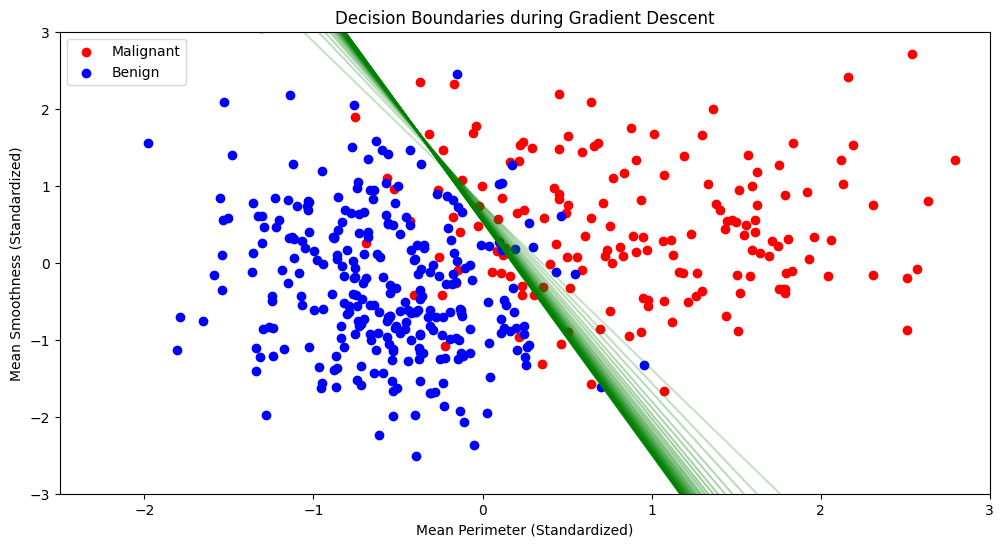

In [18]:
# Plot a single decision boundary for given weights
def plot_decision_boundary(w, X, y, step, total_steps):
    x_values = np.array([X[:, 0].min() - 1, X[:, 0].max() + 1])

    # Compute corresponding y-values for the boundary
    if w[1] != 0:
        y_values = -(w[0] * x_values + w[2]) / w[1]
        # Draw boundary with increasing opacity over steps
        plt.plot(x_values, y_values, color='green',
                 alpha=(0.20 + (step / total_steps) * 0.20))
    else:
        # Vertical line if w[1] == 0
        plt.axvline(x=-w[2] / w[0], color='green')

    plt.legend()


# Plot all decision boundaries throughout training
def plot_decision_boundaries(weights_history, X, y, total_steps):

    plt.figure(figsize=(12, 6))

    # Plot data points by class
    plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', label='Malignant')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Benign')

    # Set plot limits
    plt.xlim(-2.5, 3)
    plt.ylim(-3, 3)

    # Plot decision boundaries for selected training steps
    for i, w in enumerate(weights_history):
        if i % 10 == 0:
            step = i * 10
            plot_decision_boundary(w, X, y, step, total_steps)

    plt.title('Decision Boundaries during Gradient Descent')
    plt.xlabel('Mean Perimeter (Standardized)')
    plt.ylabel('Mean Smoothness (Standardized)')
    plt.show()


plot_decision_boundaries(weights_history, X_train[:, :2], y_train, n_steps)